# Session review — R4/R5/R6 task sessions

Goal: take a first look at how the online template-matching pipeline is doing on the new rats, across all sessions where the task was actually running (i.e., have a `behavior_log.csv`). For each session this notebook:

1. Loads the rig outputs (`triang_keys_3D.npy`, `behavior_log.csv`, `template_tracker.npz`, `frame_mapping.csv`, the per-session template, the per-session water-port location).
2. Replays the rule offline by projecting the saved (corrector-output) keypoints into PC space and running the same bounds + refractory logic. This gives us *what would have fired if there were no port-exclusion gate*.
3. Compares online vs offline matches and produces plots: rate-over-time, port-exclusion distribution, online/offline agreement, `num_outside` distribution, bound trajectory, PC-space scatter, and dropped-frame analysis.
4. Builds a per-session summary DataFrame for cross-rat comparison.

Lick events live on the DANNCE side and aren't loaded here — once DANNCE catches up I'll add a follow-up cell.

**Configuration knobs are in the next cell** (rats, date range). Everything below is automatic from there.

In [132]:
# ----- CONFIG -----
RATS = ['R4', 'R5', 'R6']
DATE_START = '2026_06_05'    # inclusive — first session date to include
DATE_END   = '2026_12_31'    # inclusive
DATA_ROOT  = '/home/yutaka-sprague/olveczky_lab/Lab/CLIRB/data'
SLEAP_HZ   = 20
# -------------------

import os, sys, glob, json, warnings
from pathlib import Path
from collections import defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage import median_filter

sys.path.insert(0, '.')
from skeleton import normalize_skeleton_batch

warnings.filterwarnings('ignore', category=RuntimeWarning)
plt.rcParams['figure.dpi'] = 110
%matplotlib inline

## 1. Per-session loader

One function that takes (rat, session) and returns every rig output the session has. Returns `None` on failure (missing file, malformed data) and prints a warning, so the rest of the notebook can keep going on partial data. Caches per session to avoid re-reading large files when we re-run cells.

In [133]:
def discover_sessions(rats=RATS, date_start=DATE_START, date_end=DATE_END):
    """Return list of (rat, session) for every session in the date range that
    has triang_keys_3D.npy + frame_mapping.csv. Includes baseline sessions
    (no behavior_log.csv); those get marked has_task_log=False at load time
    so downstream cells can branch on whether the online rule was running.
    """
    out = []
    for rat in rats:
        rat_dir = os.path.join(DATA_ROOT, rat)
        if not os.path.isdir(rat_dir):
            print(f'  missing rat dir: {rat_dir}')
            continue
        for s in sorted(os.listdir(rat_dir)):
            sd = os.path.join(rat_dir, s, 'sleap')
            if not os.path.isdir(sd):
                continue
            if not (date_start <= s[:10] <= date_end):
                continue
            if not (os.path.isfile(os.path.join(sd, 'triang_keys_3D.npy'))
                    and os.path.isfile(os.path.join(sd, 'frame_mapping.csv'))):
                continue
            out.append((rat, s))
    return out

def _find_template_file(sleap_dir, rat):
    # Online code copies the loaded template into the session folder. Look
    # for any matching <rat>_template_*.npz.
    candidates = sorted(glob.glob(os.path.join(sleap_dir, f'{rat}_template_*.npz')))
    return candidates[0] if candidates else None

def _find_port_location(sleap_dir):
    matches = sorted(glob.glob(os.path.join(
        sleap_dir, 'calibration', '*', 'water_port_location.npy')))
    return matches[0] if matches else None

_session_cache = {}

def load_session(rat, session):
    """Load a session. Sessions without behavior_log.csv (baseline) are
    handled gracefully — they get `behavior_log=None`, `tracker=None`, and
    `has_task_log=False`. Downstream code should check `has_task_log` before
    using anything that comes from the online rule.
    """
    key = (rat, session)
    if key in _session_cache:
        return _session_cache[key]
    sleap_dir = os.path.join(DATA_ROOT, rat, session, 'sleap')
    out = {'rat': rat, 'session': session, 'sleap_dir': sleap_dir}
    try:
        try:
            out['triang_3d'] = np.load(os.path.join(sleap_dir, 'triang_keys_3D.npy'))
        except ValueError as ve:
            # Truncated memmap (rig crashed mid-session). Skip cleanly.
            print(f'  {rat}/{session}: triang_keys_3D.npy is corrupted/truncated — skipping. ({ve})')
            return None
        out['frame_mapping'] = pd.read_csv(
            os.path.join(sleap_dir, 'frame_mapping.csv'),
            skipinitialspace=True)
        # Behavior_times and behavior_log are only present if the rule ran.
        bt_path = os.path.join(sleap_dir, 'behavior_times.csv')
        out['behavior_times'] = (pd.read_csv(bt_path, skipinitialspace=True)
                                  if os.path.isfile(bt_path) else None)
        bl_path = os.path.join(sleap_dir, 'behavior_log.csv')
        if os.path.isfile(bl_path):
            out['behavior_log'] = pd.read_csv(bl_path, skipinitialspace=True)
            out['has_task_log'] = True
        else:
            out['behavior_log'] = None
            out['has_task_log'] = False
        # Template: prefer the per-session copy (only exists for task sessions);
        # fall back to the rat's master template.
        tmpl_path = _find_template_file(sleap_dir, rat)
        if tmpl_path is None:
            tmpl_path = os.path.join(DATA_ROOT, rat, 'templates', f'{rat}_template_1.npz')
        if not os.path.isfile(tmpl_path):
            print(f'  {rat}/{session}: no template found anywhere — skipping')
            return None
        tmpl_npz = np.load(tmpl_path, allow_pickle=True)
        out['template'] = {k: tmpl_npz[k] for k in tmpl_npz.files}
        out['template_file'] = tmpl_path
        # template_tracker only exists if the rule ran with task_id != 0.
        tracker_path = os.path.join(sleap_dir, 'template_tracker.npz')
        if os.path.isfile(tracker_path):
            tracker = np.load(tracker_path, allow_pickle=True)
            out['tracker'] = {k: tracker[k] for k in tracker.files}
        else:
            out['tracker'] = None
        port_path = _find_port_location(sleap_dir)
        if port_path is None:
            print(f'  {rat}/{session}: no water_port_location.npy found')
            out['port_xy'] = None
        else:
            port = np.load(port_path)
            out['port_xy'] = np.asarray(port).ravel()[:3]
        # min_port_distance from campy_config.yaml if present.
        out['min_port_distance'] = 200.0
        cfg_path = os.path.join(sleap_dir, 'campy_config.yaml')
        if os.path.isfile(cfg_path):
            with open(cfg_path) as f:
                for line in f:
                    if 'min_port_distance' in line and ':' in line:
                        try:
                            out['min_port_distance'] = float(line.split(':', 1)[1].split('#')[0].strip())
                        except Exception:
                            pass
                        break
    except Exception as e:
        print(f'  {rat}/{session}: load failed — {e!r}')
        return None
    _session_cache[key] = out
    return out

SESSIONS = discover_sessions()
print(f'discovered {len(SESSIONS)} sessions:')
for rat, s in SESSIONS:
    print(f'  {rat}/{s}')

discovered 51 sessions:
  R4/2026_06_05_1
  R4/2026_06_08_1
  R4/2026_06_09_1
  R4/2026_06_11_1
  R4/2026_06_12_1
  R4/2026_06_15_1
  R4/2026_06_16_1
  R4/2026_06_17_1
  R4/2026_06_18_1
  R4/2026_06_18_2
  R4/2026_06_19_1
  R4/2026_06_20_1
  R4/2026_06_22_1
  R4/2026_06_22_2
  R4/2026_06_23_1
  R4/2026_06_23_2
  R4/2026_06_24_1
  R5/2026_06_05_1
  R5/2026_06_08_1
  R5/2026_06_09_1
  R5/2026_06_11_1
  R5/2026_06_12_1
  R5/2026_06_15_1
  R5/2026_06_16_1
  R5/2026_06_17_1
  R5/2026_06_18_1
  R5/2026_06_18_2
  R5/2026_06_19_1
  R5/2026_06_20_1
  R5/2026_06_22_1
  R5/2026_06_22_2
  R5/2026_06_23_1
  R5/2026_06_24_1
  R6/2026_06_05_1
  R6/2026_06_08_1
  R6/2026_06_09_1
  R6/2026_06_11_1
  R6/2026_06_12_1
  R6/2026_06_15_1
  R6/2026_06_16_1
  R6/2026_06_17_1
  R6/2026_06_18_1
  R6/2026_06_18_2
  R6/2026_06_19_1
  R6/2026_06_19_2
  R6/2026_06_20_1
  R6/2026_06_22_1
  R6/2026_06_22_2
  R6/2026_06_23_1
  R6/2026_06_23_2
  R6/2026_06_24_1


## 2. Offline replay of the rule

Reproduces what `TemplateMatch` does online, applied to the saved (corrector-output) `triang_keys_3D.npy`. Same steps:

1. z-flip then `normalize_skeleton_batch` (xy rotation around SpineM is z-independent, so flip order doesn't matter; matches both the online `behavior.py` pipeline and the offline notebooks).
2. Apply the rule's 5-frame causal median in keypoint space (mirrors `behavior_rule.py:corrections`).
3. Subtract `feature_means`, project onto `pc_weights`, take `pcs_to_use`.
4. Slide a 30-frame window over PC space; flag matches with `num_outside_bounds <= accepted_errors` (defaults to 3, matches the rig config).
5. Enforce a refractory period of `template_length / fps` (= 30/20 = 1.5 s) after each match.

Returns: dataframe with one row per processed-frame (PC1/PC2, num_outside, match_fired_offline), plus the list of online matches read straight from `behavior_log.csv`.

In [134]:
def _causal_median_5_kp(triang):
    """5-frame causal median in keypoint space, matching `behavior_rule.corrections`.
    triang: (T, 23, 3). Output same shape.
    """
    pad = 4
    padded = np.concatenate([np.repeat(triang[:1], pad, axis=0), triang], axis=0)
    T = triang.shape[0]
    widx = np.arange(T)[:, None] + np.arange(5)[None, :]
    return np.median(padded[widx], axis=1).astype(np.float32)

def project_session_to_pcs(sd):
    """Run the full kp -> PC projection on the session's corrected triang_3d.
    Returns (T, n_features) array of all PC columns.

    Critically, this MATCHES the online rule's order of operations:
      1. z-flip + normalize_skeleton (per frame)
      2. 5-frame causal median across the *rotated* keypoints
      3. subtract feature_means, project via pc_weights
    Originally this cell medianed the raw keypoints *before* normalization,
    which doesn't commute with the per-frame skeleton rotation and produces
    slightly different PCs than the online rule actually computed. Confirmed
    by comparing offline PC values against the online behavior_log.csv on
    R4/2026_06_18_1 frame 3855: median-after matches the online log to ~1
    unit, median-before is off by ~3 units.
    """
    triang = sd['triang_3d'].astype(np.float32)
    flipped = triang.copy()
    flipped[:, :, 2] = -flipped[:, :, 2]
    rotated, _, _ = normalize_skeleton_batch(flipped)
    rotated_med = _causal_median_5_kp(rotated)
    flat = rotated_med.reshape(rotated_med.shape[0], -1)
    tmpl = sd['template']
    centered = flat - tmpl['feature_means']
    pcs = centered @ tmpl['pc_weights'].T
    return pcs  # (T, 69)

def replay_rule_offline(sd, accepted_errors=3, bounds_scalar=None):
    """Replay the TemplateMatch rule on the session's corrected triang_3d.

    Returns (match_frames, num_outside_per_frame, pc_array). match_frames is
    indexed against the cam0/triang_3d timeline. The refractory window is
    enforced (template_length / fps seconds).
    """
    tmpl = sd['template']
    pcs_to_use = np.asarray(tmpl['pcs_to_use']).ravel().astype(int)
    template = tmpl['template'][:, :len(pcs_to_use)]    # (30, n_pcs)
    if 'bounds_to_use' in tmpl:
        bounds_arr = tmpl['bounds_to_use']               # (30, n_pcs) - per-frame
    else:
        # fallback to flat bounds across the template window
        scalar = float(tmpl['bounds']) if bounds_scalar is None else bounds_scalar
        feature_stds = tmpl['feature_stds'][pcs_to_use]
        bounds_arr = np.tile(feature_stds * scalar, (template.shape[0], 1))
    # If the caller specified a different bounds scalar, rescale.
    if bounds_scalar is not None and 'bounds_to_use' in tmpl:
        scalar = float(bounds_scalar) / float(tmpl['bounds'])
        bounds_arr = bounds_arr * scalar

    pcs_full = project_session_to_pcs(sd)                # (T, 69)
    pcs = pcs_full[:, pcs_to_use]                        # (T, n_pcs)
    T, n_pc = pcs.shape
    win = template.shape[0]                              # 30
    refractory_frames = win                              # template_length / fps in frames at SLEAP_HZ

    # Sliding window: for each t >= win-1, look at pcs[t-win+1:t+1] and count
    # how many (frame, pc) pairs are outside template ± bounds.
    if T < win:
        return np.array([]), np.full(T, np.nan), pcs_full
    # vectorized num_outside per t
    # windows shape (T-win+1, win, n_pc)
    arange_t = np.arange(win, dtype=np.int64)
    base = np.arange(T - win + 1, dtype=np.int64)[:, None]
    windows = pcs[base + arange_t]                       # (T-win+1, win, n_pc)
    above = windows >= (template + bounds_arr)
    below = windows <= (template - bounds_arr)
    outside_count = (above | below).reshape(windows.shape[0], -1).sum(axis=1)
    # align to last-frame-in-window indexing
    num_outside = np.full(T, np.nan)
    num_outside[win - 1:] = outside_count

    # Sweep matches with refractory.
    matches = []
    last_match = -refractory_frames
    for t in range(win - 1, T):
        if outside_count[t - (win - 1)] <= accepted_errors and (t - last_match) >= refractory_frames:
            matches.append(t)
            last_match = t
    return np.array(matches, dtype=int), num_outside, pcs_full

## 3. Online ↔ offline alignment + port distance

The online `behavior_log.csv` is indexed by **processed_frame** (one row per SLEAP forward pass, length ~24000). The offline replay is run on `triang_keys_3D.npy`, indexed by **cam0_frame** (length ~36000, with linear interpolation filling dropped-frame gaps). The bridge is `frame_mapping.csv` — every processed_frame has a cam0_frame.

For each online trigger row, find the corresponding cam0_frame so we can compare it head-to-head with offline matches. Then compute distance to the water port at every offline match, using the saved `triang_3d` (which is what the rig had access to).

In [135]:
def compute_session_analysis(sd, accepted_errors=3, port_match_tol_frames=5):
    """Run offline replay + cross-reference with the online log.

    For baseline sessions (sd['has_task_log']==False), runs only the offline
    replay; online arrays come back empty so downstream code can keep its
    shape but the rat had no task running.

    Returns dict with per-event arrays and a summary dict.
    """
    fm = sd['frame_mapping']
    pf_to_cam0 = fm['cam0_frame'].to_numpy(dtype=int)
    pf_to_acq  = fm['cam0_acquisition_time'].to_numpy(dtype=float)

    triang = sd['triang_3d']

    if sd['has_task_log']:
        log = sd['behavior_log']
        online_trig_pf = log.loc[log['triggered'] == 1, 'frame'].to_numpy(dtype=int)
        online_trig_pf = online_trig_pf[online_trig_pf < len(pf_to_cam0)]
        online_trig_cam0 = pf_to_cam0[online_trig_pf]
        # Per-row cam0 frame + valid mask (used to compute log['cam0_frame']).
        log_cam0 = pf_to_cam0[np.clip(log['frame'].to_numpy(dtype=int), 0,
                                        len(pf_to_cam0) - 1)]
        valid_log = log_cam0 < len(triang)
        log = log.iloc[:len(valid_log)].copy()
        log['cam0_frame'] = log_cam0
        log['valid'] = valid_log
        log = log[log['valid']].drop(columns=['valid'])
    else:
        online_trig_pf = np.array([], dtype=int)
        online_trig_cam0 = np.array([], dtype=int)
        log = None

    # Offline replay always runs.
    offline_match_cam0, num_outside_cam0, pcs_full = replay_rule_offline(
        sd, accepted_errors=accepted_errors)

    # Port distance at every cam0 frame.
    if sd['port_xy'] is not None:
        port_xy = np.asarray(sd['port_xy']).ravel()[:2]
        com_xy = triang.mean(axis=1)[:, :2]
        port_dist = np.linalg.norm(com_xy - port_xy[None, :], axis=1)
    else:
        port_dist = np.full(len(triang), np.nan)

    offline_match_dist = port_dist[offline_match_cam0] if len(offline_match_cam0) else np.array([])
    online_trig_dist = port_dist[online_trig_cam0] if len(online_trig_cam0) else np.array([])

    # Online/offline agreement (only meaningful for task sessions).
    onset_arr = online_trig_cam0
    off_arr = offline_match_cam0
    both = np.zeros(len(onset_arr), dtype=bool)
    off_matched = np.zeros(len(off_arr), dtype=bool)
    if len(onset_arr) and len(off_arr):
        for i, f in enumerate(onset_arr):
            diffs = np.abs(off_arr - f)
            j = int(np.argmin(diffs))
            if diffs[j] <= port_match_tol_frames and not off_matched[j]:
                both[i] = True
                off_matched[j] = True

    online_only = onset_arr[~both]
    offline_only = off_arr[~off_matched]
    intersect = onset_arr[both]

    # Dropped frames: cam0 advances faster than processed_frame.
    n_processed = len(pf_to_cam0)
    n_cam0_max = int(pf_to_cam0.max()) + 1 if n_processed else 0
    drop_rate = 1.0 - (n_processed / max(n_cam0_max, 1))

    return {
        'sd': sd,
        'online_trig_pf': online_trig_pf,
        'online_trig_cam0': online_trig_cam0,
        'online_trig_dist': online_trig_dist,
        'offline_match_cam0': offline_match_cam0,
        'offline_match_dist': offline_match_dist,
        'num_outside_cam0': num_outside_cam0,
        'pcs_full': pcs_full,
        'port_dist': port_dist,
        'intersect_cam0': intersect,
        'online_only_cam0': online_only,
        'offline_only_cam0': offline_only,
        'drop_rate': drop_rate,
        'log': log,
    }

RESULTS = {}
for rat, s in SESSIONS:
    sd = load_session(rat, s)
    if sd is None:
        continue
    RESULTS[(rat, s)] = compute_session_analysis(sd)
    r = RESULTS[(rat, s)]
    task_marker = '' if sd['has_task_log'] else '  [BASELINE — no online rule]'
    print(f"{rat}/{s}: online_trig={len(r['online_trig_cam0'])}  "
          f"offline_match={len(r['offline_match_cam0'])}  "
          f"both={len(r['intersect_cam0'])}  "
          f"dropped={r['drop_rate']*100:.1f}%{task_marker}")

R4/2026_06_05_1: online_trig=0  offline_match=4  both=0  dropped=1.5%  [BASELINE — no online rule]
R4/2026_06_08_1: online_trig=0  offline_match=5  both=0  dropped=1.6%  [BASELINE — no online rule]
R4/2026_06_09_1: online_trig=0  offline_match=18  both=0  dropped=5.2%  [BASELINE — no online rule]
R4/2026_06_11_1: online_trig=6  offline_match=8  both=6  dropped=6.3%
R4/2026_06_12_1: online_trig=16  offline_match=20  both=16  dropped=6.3%
R4/2026_06_15_1: online_trig=9  offline_match=18  both=9  dropped=49.9%
R4/2026_06_16_1: online_trig=7  offline_match=15  both=7  dropped=6.9%
R4/2026_06_17_1: online_trig=16  offline_match=22  both=16  dropped=5.8%
R4/2026_06_18_1: online_trig=5  offline_match=14  both=5  dropped=10.5%
R4/2026_06_18_2: online_trig=18  offline_match=34  both=18  dropped=6.2%
R4/2026_06_19_1: online_trig=33  offline_match=59  both=33  dropped=11.4%
R4/2026_06_20_1: online_trig=32  offline_match=53  both=32  dropped=5.5%
R4/2026_06_22_1: online_trig=23  offline_match=41  

## 4. Cross-session summary table

One row per session. Useful as a single-glance overview.

In [136]:
def session_summary_row(r):
    sd = r['sd']
    triang_len = len(sd['triang_3d'])
    duration_min = triang_len / SLEAP_HZ / 60.0
    min_port = sd['min_port_distance']
    off_dist = r['offline_match_dist']
    inside_exclusion = (off_dist < min_port).sum() if len(off_dist) else 0
    out_exclusion = (off_dist >= min_port).sum() if len(off_dist) else 0
    tracker = sd.get('tracker') or {}
    bounds_final = float(tracker['bounds'][-1]) if 'bounds' in tracker and len(tracker['bounds']) else np.nan
    return {
        'rat': sd['rat'],
        'session': sd['session'],
        'task': sd['has_task_log'],
        'duration_min': duration_min,
        'dropped_pct': r['drop_rate'] * 100,
        'n_online_trig': len(r['online_trig_cam0']),
        'n_offline_match': len(r['offline_match_cam0']),
        'n_both': len(r['intersect_cam0']),
        'n_online_only': len(r['online_only_cam0']),
        'n_offline_only': len(r['offline_only_cam0']),
        'rate_online_per_min': len(r['online_trig_cam0']) / max(duration_min, 1e-3),
        'rate_offline_per_min': len(r['offline_match_cam0']) / max(duration_min, 1e-3),
        'offline_inside_exclusion': inside_exclusion,
        'offline_outside_exclusion': out_exclusion,
        'median_port_dist_offline': float(np.median(off_dist)) if len(off_dist) else np.nan,
        'median_port_dist_online': float(np.median(r['online_trig_dist'])) if len(r['online_trig_dist']) else np.nan,
        'min_port_distance_mm': min_port,
        'bounds_final': bounds_final,
    }

summary_rows = [session_summary_row(r) for r in RESULTS.values()]
summary = pd.DataFrame(summary_rows).sort_values(['rat', 'session']).reset_index(drop=True)
summary

,rat,session,task,duration_min,dropped_pct,n_online_trig,n_offline_match,n_both,n_online_only,n_offline_only,rate_online_per_min,rate_offline_per_min,offline_inside_exclusion,offline_outside_exclusion,median_port_dist_offline,median_port_dist_online,min_port_distance_mm,bounds_final
0,R4,2026_06_05_1,False,20.0,1.550000,0,4,0,0,4,0.000000,0.200000,2,2,216.767813,NaN,200.0,NaN
1,R4,2026_06_08_1,False,20.0,1.575000,0,5,0,0,5,0.000000,0.250000,1,4,240.060822,NaN,200.0,NaN
2,R4,2026_06_09_1,False,20.0,5.237500,0,18,0,0,18,0.000000,0.900000,6,12,249.163812,NaN,200.0,NaN
3,R4,2026_06_11_1,True,45.0,6.342593,6,8,6,0,2,0.133333,0.177778,2,6,412.199534,450.551615,200.0,1.0
4,R4,2026_06_12_1,True,45.0,6.261111,16,20,16,0,4,0.355556,0.444444,2,18,337.701194,410.962625,200.0,1.0
5,R4,2026_06_15_1,True,35.0,49.878571,9,18,9,0,9,0.257143,0.514286,7,11,301.150559,354.390356,200.0,1.0
6,R4,2026_06_16_1,True,35.0,6.923810,7,15,7,0,8,0.200000,0.428571,7,8,232.683184,482.973366,200.0,1.0
7,R4,2026_06_17_1,True,35.0,5.802381,16,22,16,0,6,0.457143,0.628571,6,16,434.693742,468.398710,200.0,1.0
8,R4,2026_06_18_1,True,35.0,10.538095,5,14,5,0,9,0.142857,0.400000,8,6,131.217556,482.275007,200.0,1.0
9,R4,2026_06_18_2,True,35.0,6.178571,18,34,18,0,16,0.514286,0.971429,16,18,218.051736,463.413322,200.0,1.0


## 5a. Match rate over time

For each session, plot online triggers and offline matches as a 60-second rolling rate. A flat line means the rule fires consistently; a declining line means matches dropped off (either rat behavior changed or bounds tightened too far). Compare online vs offline within the same panel — the gap is roughly the port-exclusion suppression rate.

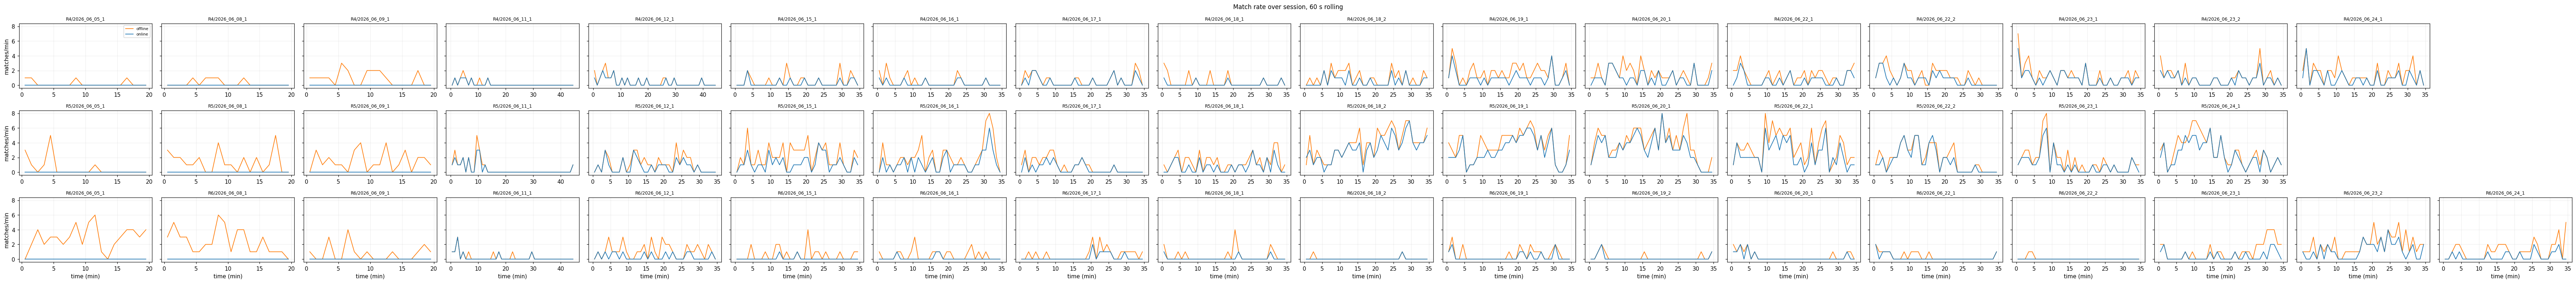

In [137]:
def rolling_rate(frames, total_len, hz=SLEAP_HZ, window_s=60.0):
    """Return time axis (minutes) and matches-per-minute rolling rate."""
    n_bins = max(int(np.ceil(total_len / hz / window_s)), 1)
    bin_edges_frames = np.linspace(0, total_len, n_bins + 1).astype(int)
    counts, _ = np.histogram(frames, bins=bin_edges_frames)
    # convert counts/bin to matches/minute
    bin_duration_min = (bin_edges_frames[1] - bin_edges_frames[0]) / hz / 60.0
    rate = counts / max(bin_duration_min, 1e-9)
    t = (bin_edges_frames[:-1] + bin_edges_frames[1:]) / 2.0 / hz / 60.0
    return t, rate

by_rat = defaultdict(list)
for (rat, s), r in RESULTS.items():
    by_rat[rat].append((s, r))

if RESULTS:
    n_rats = len(by_rat)
    max_sessions = max(len(v) for v in by_rat.values())
    fig, axes = plt.subplots(n_rats, max_sessions, figsize=(3.6 * max_sessions, 2.4 * n_rats),
                              sharex=False, sharey=True, squeeze=False)
    for i, rat in enumerate(sorted(by_rat)):
        for j, (s, r) in enumerate(sorted(by_rat[rat])):
            ax = axes[i, j]
            total_len = len(r['sd']['triang_3d'])
            t_on, rate_on = rolling_rate(r['online_trig_cam0'], total_len)
            t_off, rate_off = rolling_rate(r['offline_match_cam0'], total_len)
            ax.plot(t_off, rate_off, color='#ff7f0e', lw=1.2, label='offline')
            ax.plot(t_on, rate_on, color='#1f77b4', lw=1.2, label='online')
            ax.set_title(f'{rat}/{s}', fontsize=8)
            ax.grid(alpha=0.2)
            if j == 0:
                ax.set_ylabel('matches/min')
            if i == n_rats - 1:
                ax.set_xlabel('time (min)')
        # blank out unused columns
        for j in range(len(by_rat[rat]), max_sessions):
            axes[i, j].axis('off')
    axes[0, 0].legend(fontsize=7, loc='upper right')
    fig.suptitle('Match rate over session, 60 s rolling', fontsize=11)
    fig.tight_layout()
    plt.show()

## 5b. Port-exclusion analysis

Two views:

- **Distance distribution.** For every offline match, the rat's COM-distance to the water port. A vertical line marks the configured exclusion radius (`min_port_distance`, typically 200 mm). Matches *left of* the line are what the online rule suppressed via the port-distance gate.
- **Time × distance scatter.** Same offline matches plotted as (time, distance). Color-coded by whether the online rule fired for that match. If you see lots of offline matches *outside* the exclusion radius that the rule still suppressed, that's a refractory clash or a bounds drift between online and offline. If you see most matches concentrated near the port, the rat is template-matching while it's drinking — expected if the template was anchored on a port-approach motion.

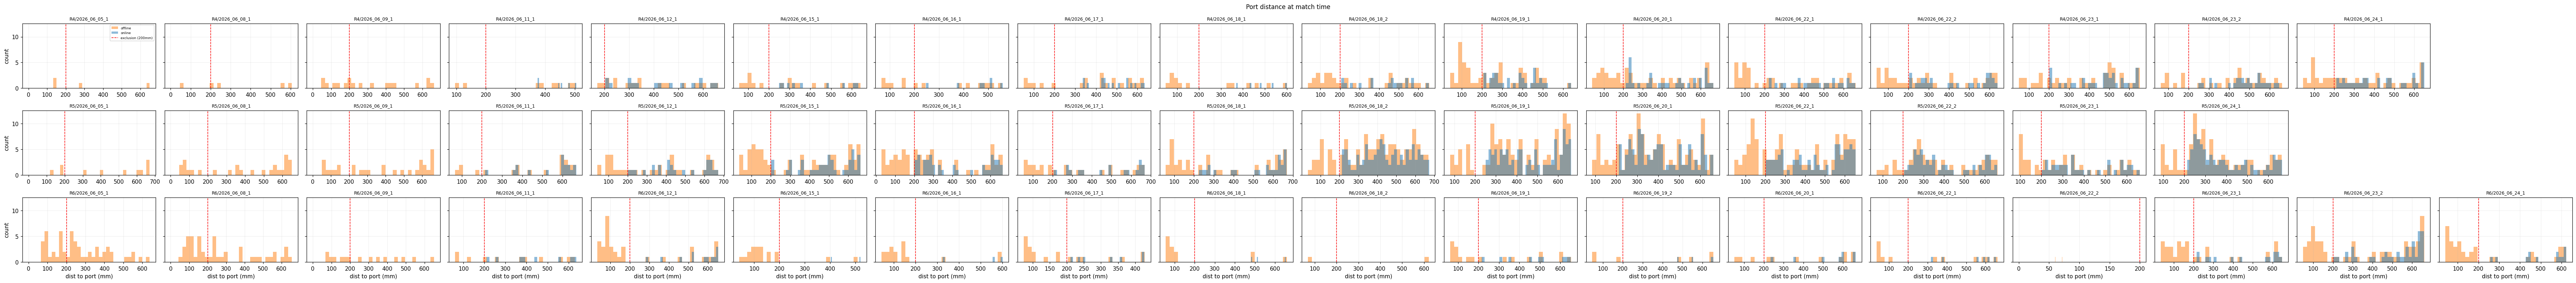

In [138]:
if RESULTS:
    fig, axes = plt.subplots(n_rats, max_sessions, figsize=(3.6 * max_sessions, 2.4 * n_rats),
                              squeeze=False, sharey=True)
    for i, rat in enumerate(sorted(by_rat)):
        for j, (s, r) in enumerate(sorted(by_rat[rat])):
            ax = axes[i, j]
            off_dist = r['offline_match_dist']
            on_dist = r['online_trig_dist']
            min_port = r['sd']['min_port_distance']
            ax.hist(off_dist[np.isfinite(off_dist)], bins=30,
                    color='#ff7f0e', alpha=0.5, label='offline')
            ax.hist(on_dist[np.isfinite(on_dist)], bins=30,
                    color='#1f77b4', alpha=0.5, label='online')
            ax.axvline(min_port, color='r', linestyle='--', lw=1,
                       label=f'exclusion ({min_port:.0f}mm)')
            ax.set_title(f'{rat}/{s}', fontsize=8)
            ax.grid(alpha=0.2)
            if i == n_rats - 1:
                ax.set_xlabel('dist to port (mm)')
            if j == 0:
                ax.set_ylabel('count')
        for j in range(len(by_rat[rat]), max_sessions):
            axes[i, j].axis('off')
    axes[0, 0].legend(fontsize=6, loc='upper right')
    fig.suptitle('Port distance at match time', fontsize=11)
    fig.tight_layout()
    plt.show()

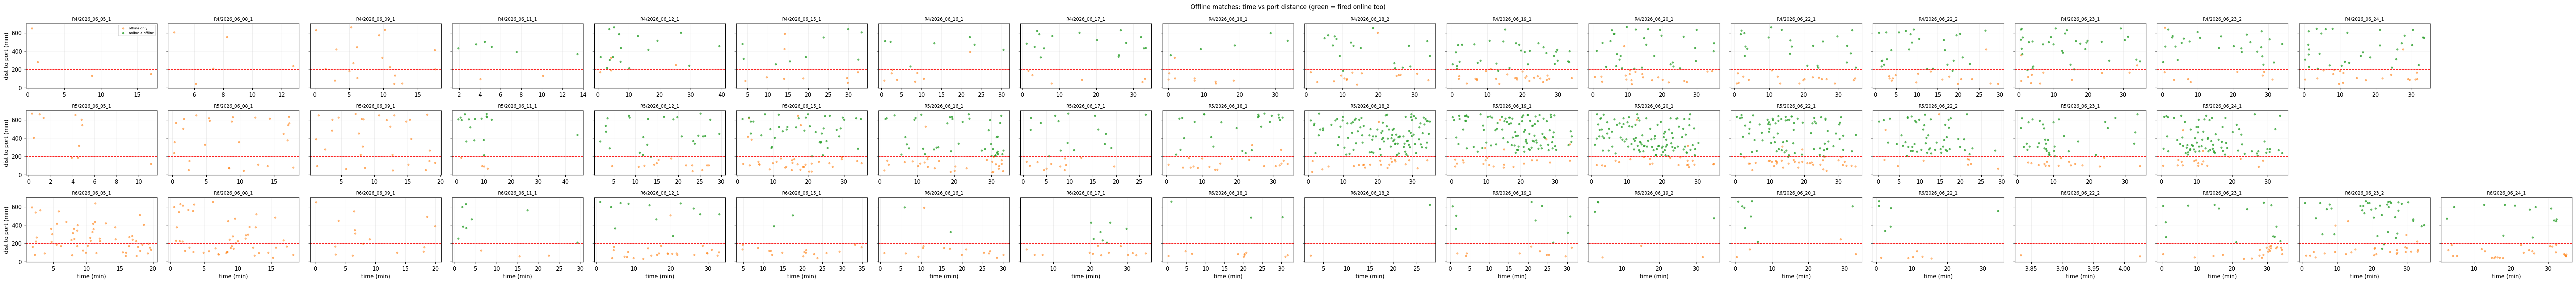

In [139]:
# Scatter: time vs distance, colored by whether the offline match fired online too.
if RESULTS:
    fig, axes = plt.subplots(n_rats, max_sessions, figsize=(3.6 * max_sessions, 2.4 * n_rats),
                              squeeze=False, sharey=True)
    for i, rat in enumerate(sorted(by_rat)):
        for j, (s, r) in enumerate(sorted(by_rat[rat])):
            ax = axes[i, j]
            off_cam0 = r['offline_match_cam0']
            off_dist = r['offline_match_dist']
            on_cam0_set = set(r['intersect_cam0'].tolist())
            # Find which offline matches were also online (within tol).
            # Approximate via a tolerance search.
            on_arr = r['online_trig_cam0']
            color_fired = np.zeros(len(off_cam0), dtype=bool)
            for k, f in enumerate(off_cam0):
                if len(on_arr) and np.min(np.abs(on_arr - f)) <= 5:
                    color_fired[k] = True
            t_min = off_cam0 / SLEAP_HZ / 60.0
            ax.scatter(t_min[~color_fired], off_dist[~color_fired],
                       c='#ff7f0e', s=8, alpha=0.5, label='offline only')
            ax.scatter(t_min[color_fired], off_dist[color_fired],
                       c='#2ca02c', s=8, alpha=0.7, label='online ∧ offline')
            min_port = r['sd']['min_port_distance']
            ax.axhline(min_port, color='r', linestyle='--', lw=1)
            ax.set_title(f'{rat}/{s}', fontsize=8)
            ax.grid(alpha=0.2)
            if i == n_rats - 1:
                ax.set_xlabel('time (min)')
            if j == 0:
                ax.set_ylabel('dist to port (mm)')
        for j in range(len(by_rat[rat]), max_sessions):
            axes[i, j].axis('off')
    axes[0, 0].legend(fontsize=6, loc='upper right')
    fig.suptitle('Offline matches: time vs port distance (green = fired online too)', fontsize=11)
    fig.tight_layout()
    plt.show()

## 5h. Dropped frames

From `frame_mapping.csv` — how many camera frames the rig dropped before SLEAP could process them. A small dropped-frame rate is normal (<5%). Anything large indicates the SLEAP forward pass is slower than the camera rate and we're falling behind, which means online matching reaction time degrades.

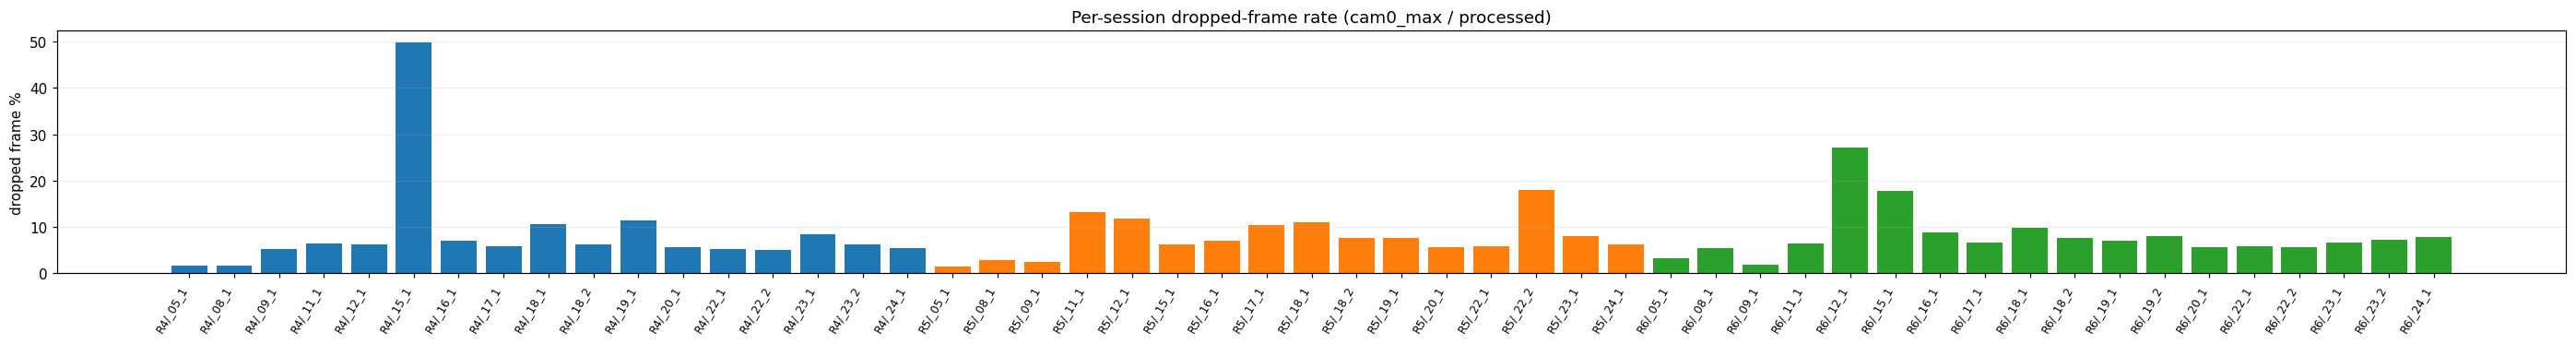

In [140]:
if RESULTS:
    fig, ax = plt.subplots(figsize=(max(8, 0.5 * len(RESULTS)), 3.5))
    labels = []; rates = []; colors = []
    rat_to_color = {'R4': '#1f77b4', 'R5': '#ff7f0e', 'R6': '#2ca02c'}
    for (rat, s) in sorted(RESULTS.keys()):
        r = RESULTS[(rat, s)]
        labels.append(f'{rat}/{s[-5:]}')
        rates.append(r['drop_rate'] * 100)
        colors.append(rat_to_color.get(rat, '#888'))
    x = np.arange(len(labels))
    ax.bar(x, rates, color=colors)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=60, fontsize=8, ha='right')
    ax.set_ylabel('dropped frame %')
    ax.set_title('Per-session dropped-frame rate (cam0_max / processed)')
    ax.grid(axis='y', alpha=0.2)
    fig.tight_layout()
    plt.show()

## 7. COM speed and rears

Two more behavioral readouts:

- **COM speed**: center-of-mass (mean of all 23 keypoints) speed per frame, then a causal 5-second (100-frame) rolling mean. Plotted per session as time × speed.
- **Rears**: contiguous periods where PC0 > 150 lasting at least 0.5 s (10 frames). A rear *ends* the first frame PC0 dips back below 150. Per-session: total rear count, count over time, duration distribution.

**PC0 polarity sanity check**: I verified for all three rats on `2026_06_17_1` that frames with `PC0 > 150` correspond to snout z ≈ −210 mm (high in the arena) vs `PC0 < -150` corresponding to snout z ≈ −10 mm (close to the floor). So `PC0 > 150` is the right rear-up direction. If the template's PC weights ever get rebuilt and the sign flips, the threshold below would need to flip too — re-run the sanity-check helper to verify.

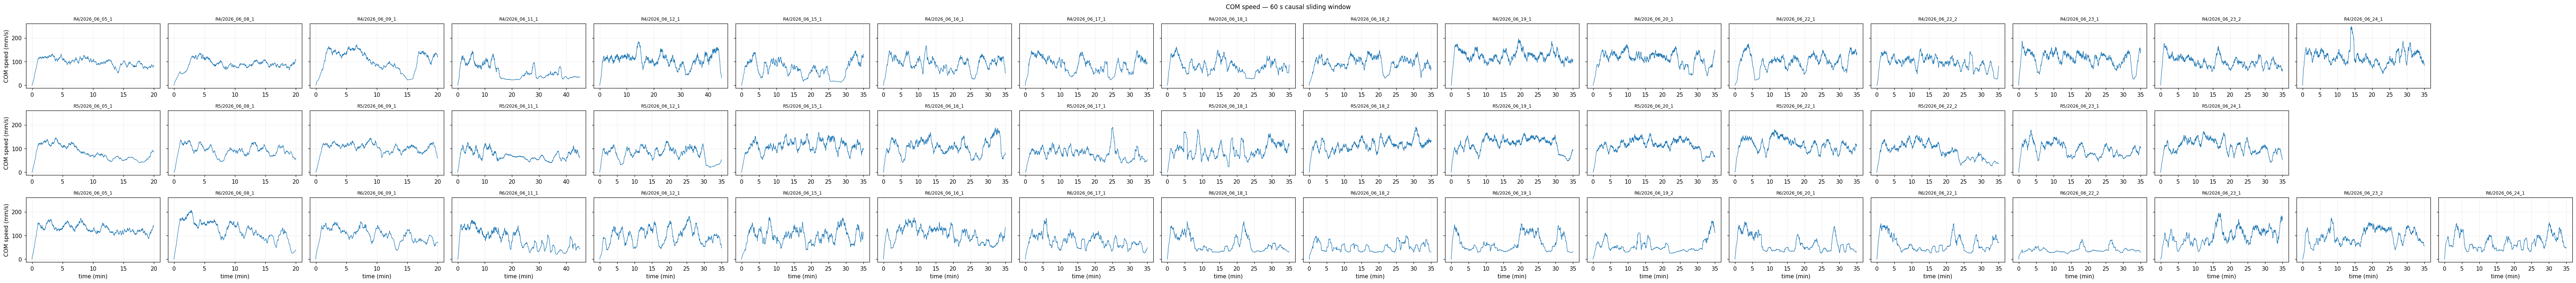

In [141]:
def compute_com_speed(triang, hz=SLEAP_HZ):
    """Return (T,) array of mm/s COM speed. First frame is 0."""
    com = triang.mean(axis=1)              # (T, 3)
    d = np.diff(com, axis=0)
    inst_speed = np.linalg.norm(d, axis=1) * hz   # (T-1,)
    return np.concatenate([[0.0], inst_speed]).astype(np.float32)

def rolling_mean_causal(x, window):
    """Causal rolling mean of length `window`. Edge: pad left with x[0]."""
    if window <= 1:
        return x.copy()
    pad = window - 1
    padded = np.concatenate([np.full(pad, x[0], dtype=x.dtype), x])
    csum = np.cumsum(padded, dtype=np.float64)
    out = (csum[window:] - csum[:-window]) / window
    # cumsum-based formula gives length T; align to x.
    return np.concatenate([[csum[window-1] / window], out])[:len(x)].astype(np.float32)

# Cache per session.
for (rat, s), r in RESULTS.items():
    r['com_speed'] = compute_com_speed(r['sd']['triang_3d'])
    r['com_speed_5s'] = rolling_mean_causal(r['com_speed'], window=60 * SLEAP_HZ)

if RESULTS:
    fig, axes = plt.subplots(n_rats, max_sessions,
                              figsize=(3.6 * max_sessions, 2.4 * n_rats),
                              squeeze=False, sharex=False, sharey=True)
    for i, rat in enumerate(sorted(by_rat)):
        for j, (s, r) in enumerate(sorted(by_rat[rat])):
            ax = axes[i, j]
            speed = r['com_speed_5s']
            t = np.arange(len(speed)) / SLEAP_HZ / 60.0
            ax.plot(t, speed, color='#1f77b4', lw=0.8)
            ax.set_title(f'{rat}/{s}', fontsize=8)
            ax.grid(alpha=0.2)
            if j == 0:
                ax.set_ylabel('COM speed (mm/s)')
            if i == n_rats - 1:
                ax.set_xlabel('time (min)')
        for j in range(len(by_rat[rat]), max_sessions):
            axes[i, j].axis('off')
    fig.suptitle('COM speed — 60 s causal sliding window', fontsize=11)
    fig.tight_layout()
    plt.show()

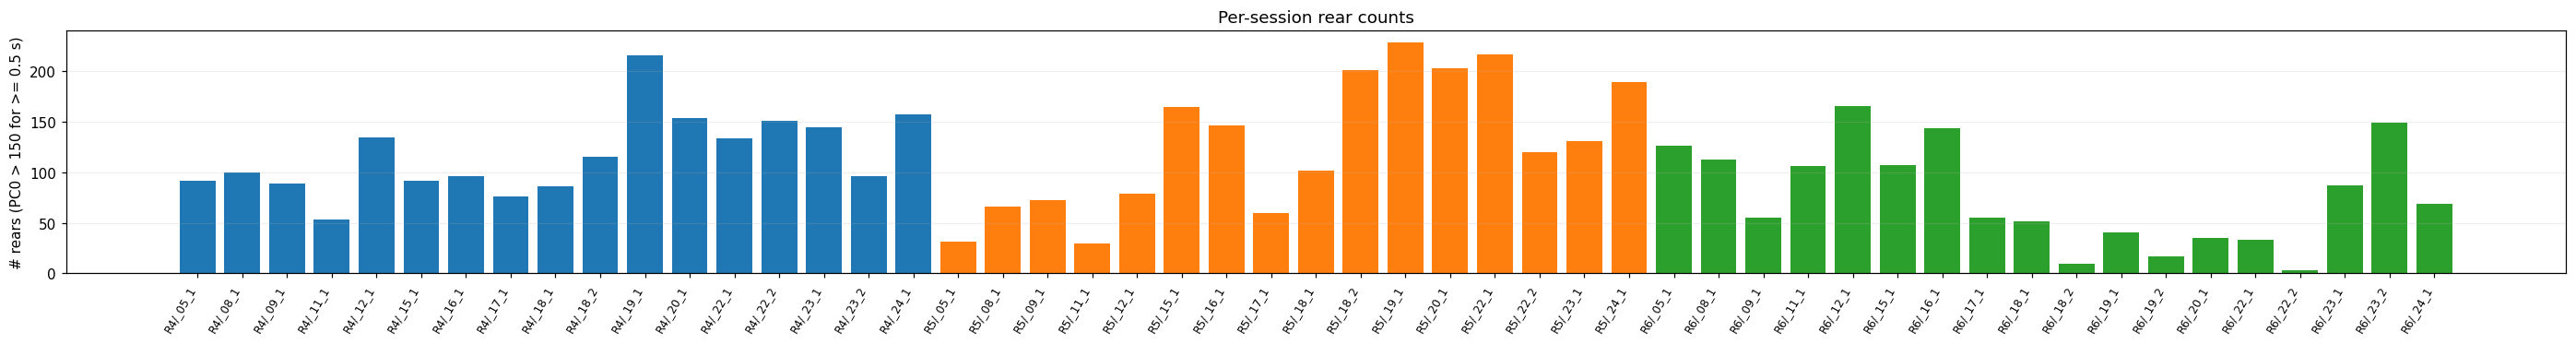

In [142]:
REAR_PC0_THRESHOLD = 150.0
REAR_MIN_FRAMES = int(0.5 * SLEAP_HZ)   # 10 frames @ 20 Hz

def detect_rears(pc0, threshold=REAR_PC0_THRESHOLD, min_frames=REAR_MIN_FRAMES):
    """Find rear bouts: runs of (pc0 > threshold) lasting >= min_frames.
    Returns list of (start_frame, end_frame_exclusive, duration_frames).
    A rear ends the first frame pc0 drops back below threshold.
    """
    above = pc0 > threshold
    if not above.any():
        return []
    # Find run boundaries.
    edges = np.diff(above.astype(np.int8))
    starts = np.where(edges == 1)[0] + 1
    ends   = np.where(edges == -1)[0] + 1
    if above[0]:
        starts = np.r_[0, starts]
    if above[-1]:
        ends = np.r_[ends, len(above)]
    out = []
    for s_idx, e_idx in zip(starts, ends):
        dur = e_idx - s_idx
        if dur >= min_frames:
            out.append((int(s_idx), int(e_idx), int(dur)))
    return out

# Cache rears + per-session totals
for (rat, s), r in RESULTS.items():
    pcs_to_use = np.asarray(r['sd']['template']['pcs_to_use']).ravel().astype(int)
    pc0 = r['pcs_full'][:, pcs_to_use[0]]
    r['pc0'] = pc0
    r['rears'] = detect_rears(pc0)
    r['n_rears'] = len(r['rears'])

# Per-session total count, bar chart per rat.
if RESULTS:
    fig, ax = plt.subplots(figsize=(max(8, 0.5 * len(RESULTS)), 3.5))
    labels = []
    counts = []
    colors = []
    rat_to_color = {'R4': '#1f77b4', 'R5': '#ff7f0e', 'R6': '#2ca02c'}
    for (rat, s) in sorted(RESULTS.keys()):
        r = RESULTS[(rat, s)]
        labels.append(f'{rat}/{s[-5:]}')
        counts.append(r['n_rears'])
        colors.append(rat_to_color.get(rat, '#888'))
    x = np.arange(len(labels))
    ax.bar(x, counts, color=colors)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=60, fontsize=8, ha='right')
    ax.set_ylabel('# rears (PC0 > 150 for >= 0.5 s)')
    ax.set_title('Per-session rear counts')
    ax.grid(axis='y', alpha=0.2)
    fig.tight_layout()
    plt.show()

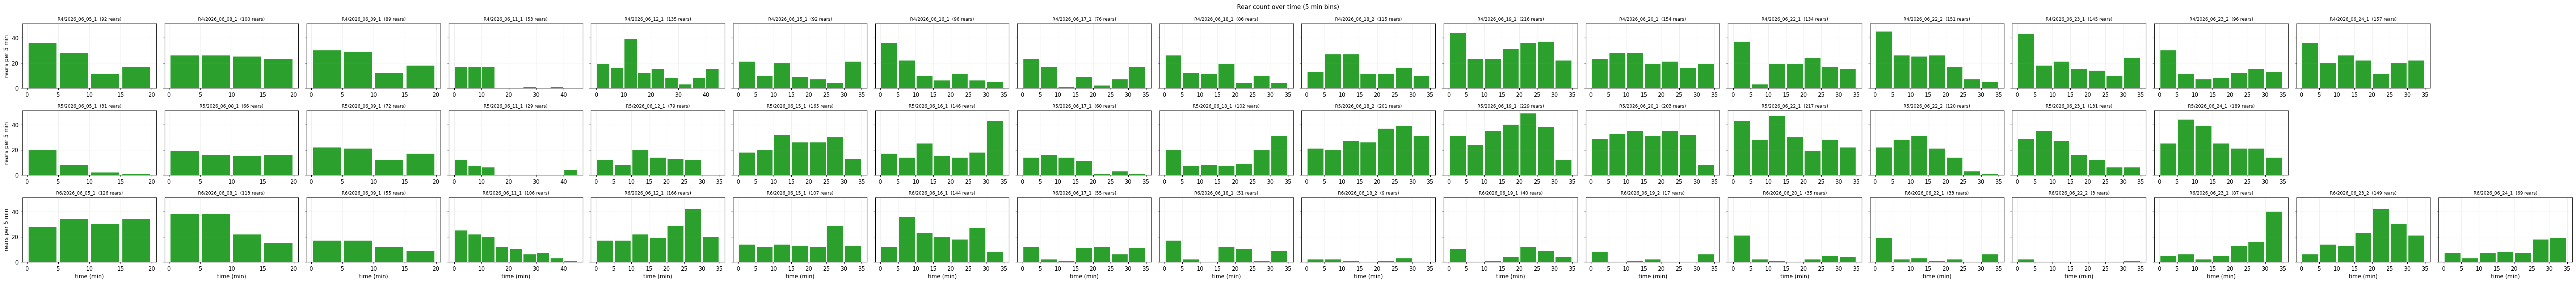

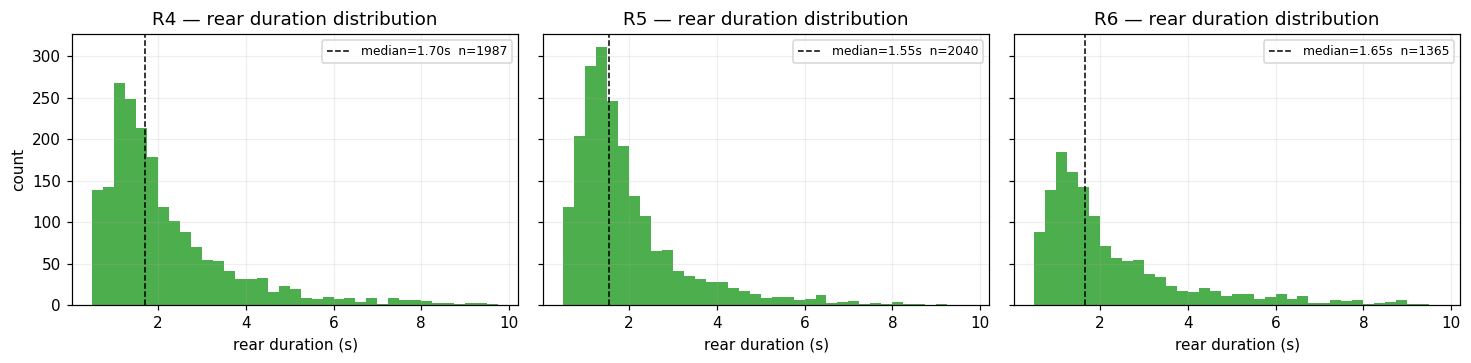

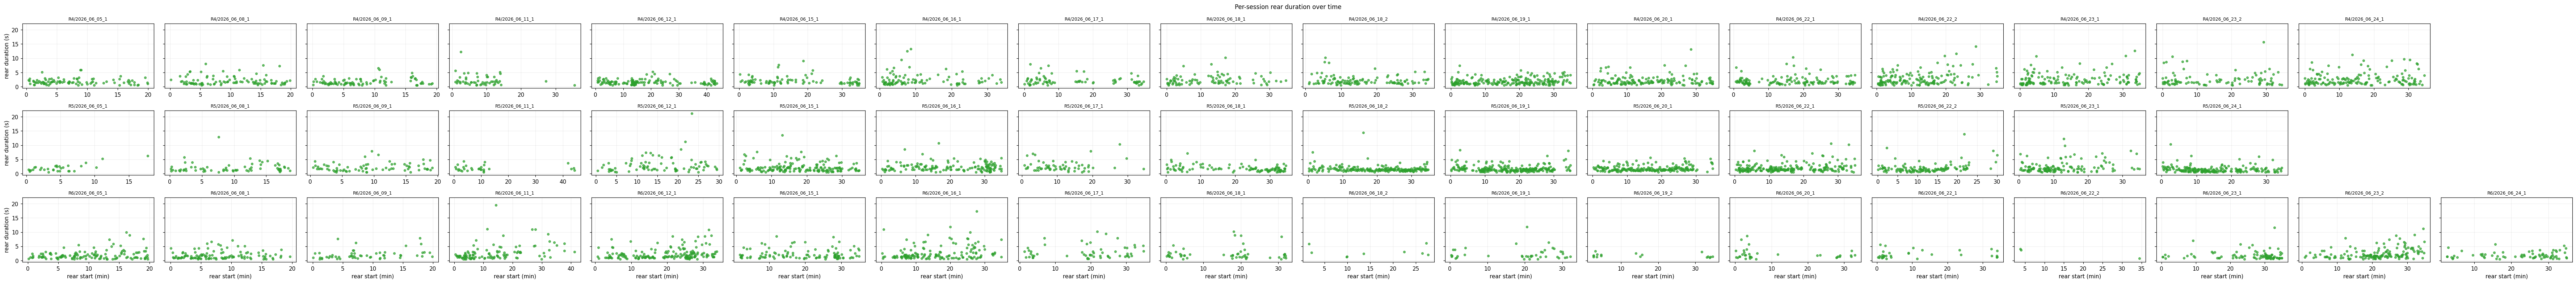

In [143]:
# Rear count over time within each session (5-minute bins).
if RESULTS:
    BIN_MIN = 5.0
    fig, axes = plt.subplots(n_rats, max_sessions,
                              figsize=(3.6 * max_sessions, 2.4 * n_rats),
                              squeeze=False, sharex=False, sharey=True)
    for i, rat in enumerate(sorted(by_rat)):
        for j, (s, r) in enumerate(sorted(by_rat[rat])):
            ax = axes[i, j]
            rears = r['rears']
            total_len = len(r['pc0'])
            duration_min = total_len / SLEAP_HZ / 60.0
            if duration_min <= 0:
                ax.axis('off'); continue
            n_bins = max(int(np.ceil(duration_min / BIN_MIN)), 1)
            bin_edges = np.linspace(0, total_len, n_bins + 1)
            rear_starts = np.array([rr[0] for rr in rears], dtype=float)
            counts, _ = np.histogram(rear_starts, bins=bin_edges)
            t_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0 / SLEAP_HZ / 60.0
            ax.bar(t_centers, counts, width=BIN_MIN * 0.9, color='#2ca02c')
            ax.set_title(f'{rat}/{s}  ({r["n_rears"]} rears)', fontsize=8)
            ax.grid(alpha=0.2)
            if j == 0:
                ax.set_ylabel(f'rears per {BIN_MIN:.0f} min')
            if i == n_rats - 1:
                ax.set_xlabel('time (min)')
        for j in range(len(by_rat[rat]), max_sessions):
            axes[i, j].axis('off')
    fig.suptitle(f'Rear count over time ({BIN_MIN:.0f} min bins)', fontsize=11)
    fig.tight_layout()
    plt.show()

# Distribution of rear durations, per rat (pooled across that rat's sessions).
if RESULTS:
    fig, axes = plt.subplots(1, n_rats, figsize=(4.5 * n_rats, 3.4),
                              squeeze=False, sharey=True)
    for i, rat in enumerate(sorted(by_rat)):
        ax = axes[0, i]
        durations_s = []
        for s, r in sorted(by_rat[rat]):
            durations_s.extend([d / SLEAP_HZ for (_, _, d) in r['rears']])
        if durations_s:
            ax.hist(durations_s, bins=np.arange(0.5, 10.0, 0.25),
                    color='#2ca02c', alpha=0.85)
            med = np.median(durations_s)
            ax.axvline(med, color='k', linestyle='--', lw=1,
                       label=f'median={med:.2f}s  n={len(durations_s)}')
            ax.legend(fontsize=8)
        ax.set_xlabel('rear duration (s)')
        ax.set_title(f'{rat} — rear duration distribution')
        ax.grid(alpha=0.2)
    axes[0, 0].set_ylabel('count')
    fig.tight_layout()
    plt.show()

# Per-session rear-duration scatter (start_time vs duration), so you can see
# whether rears get shorter / longer through the session.
if RESULTS:
    fig, axes = plt.subplots(n_rats, max_sessions,
                              figsize=(3.6 * max_sessions, 2.4 * n_rats),
                              squeeze=False, sharex=False, sharey=True)
    for i, rat in enumerate(sorted(by_rat)):
        for j, (s, r) in enumerate(sorted(by_rat[rat])):
            ax = axes[i, j]
            rears = r['rears']
            if not rears:
                ax.set_title(f'{rat}/{s}  (no rears)', fontsize=8)
                ax.grid(alpha=0.2); continue
            starts_min = np.array([rr[0] for rr in rears]) / SLEAP_HZ / 60.0
            durs_s    = np.array([rr[2] for rr in rears]) / SLEAP_HZ
            ax.scatter(starts_min, durs_s, s=14, c='#2ca02c', alpha=0.7)
            ax.set_title(f'{rat}/{s}', fontsize=8)
            ax.grid(alpha=0.2)
            if j == 0:
                ax.set_ylabel('rear duration (s)')
            if i == n_rats - 1:
                ax.set_xlabel('rear start (min)')
        for j in range(len(by_rat[rat]), max_sessions):
            axes[i, j].axis('off')
    fig.suptitle('Per-session rear duration over time', fontsize=11)
    fig.tight_layout()
    plt.show()

### Rears that resulted in matches — split by port exclusion

For each rear bout (PC0 > 150 for ≥ 0.5 s), check whether any offline match's template-window overlaps the rear interval. The template is a 30-frame (1.5 s) sub-portion of a rear and can be anchored on the onset, plateau, or end — so the right inclusion rule is:

> A match at frame F (template window [F-29, F]) counts toward a rear if **either F-29 or F lies inside [rear_start, rear_end)**.

This cell also **splits rears by whether they started inside the water-port exclusion radius** (using COM distance to the port at rear-start frame, vs the rig's `min_port_distance`). The two groups give independent rear-match rates:

- **Inside port (red)**: rears that the online rule would *suppress* via the port-distance gate, regardless of template match. The match rate here tells you whether the template fires when the rat is at the port.
- **Outside port (blue)**: rears in the open arena — these are the rears the online rule could actually reward.

If the red and blue curves are similar, the template fires equally well in both regions. If red is much higher, the template was anchored on a port-approach posture (common failure mode where the rule rewards drinking-adjacent rears). If blue is much higher, the template generalizes to free-arena rears better.

Small numbers below each panel's x-axis show the bin's rear count: **red = inside, blue = outside**.

Per-session rear match statistics, split by port exclusion (port-distance threshold from config):
rat      session  n_rears  n_rears_inside_port  n_rears_outside_port  n_inside_with_match  n_outside_with_match  pct_rears_with_match  pct_inside_with_match  pct_outside_with_match  matches_per_rear
 R4 2026_06_05_1       92                   26                    66                    0                     4              4.347826               0.000000                6.060606          0.043478
 R4 2026_06_08_1      100                   35                    65                    2                     3              5.000000               5.714286                4.615385          0.050000
 R4 2026_06_09_1       89                   32                    57                    7                    11             20.224719              21.875000               19.298246          0.202247
 R4 2026_06_11_1       53                   26                    27                    3                 

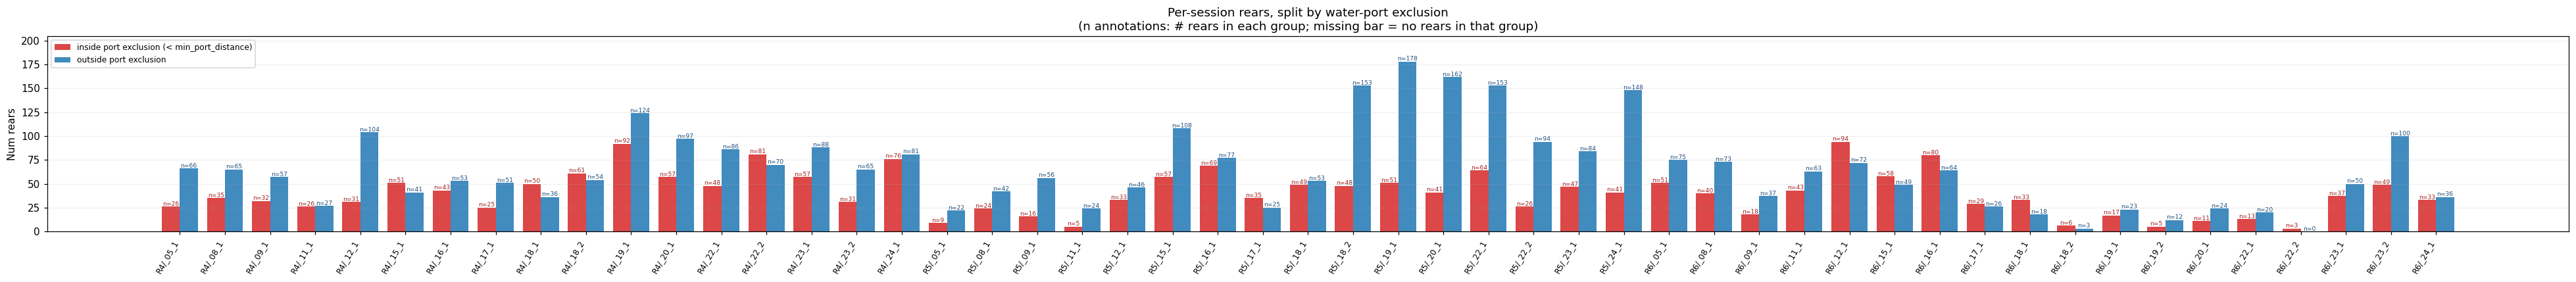

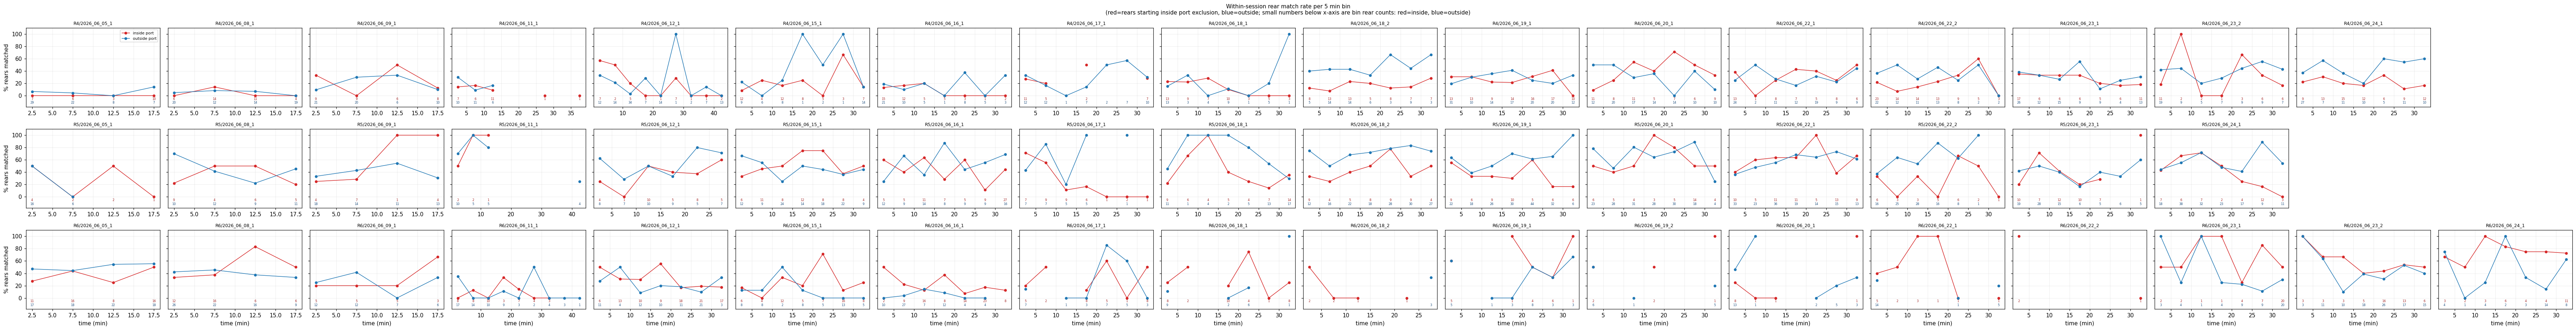

In [144]:

# Local aggregation (matches what earlier plotting cells use) so this cell
# runs even if the plot cells above were skipped.
by_rat = defaultdict(list)
for (rat, s), r in RESULTS.items():
    by_rat[rat].append((s, r))
n_rats = max(len(by_rat), 1)
max_sessions = max((len(v) for v in by_rat.values()), default=1)

# ---- Match-template vs rear-interval timing ----
#
# Inclusion rule: a match counts toward a rear if either endpoint of the
# 30-frame template window (start = match_frame - 29, end = match_frame) lies
# inside the rear interval [rear_start, rear_end). See the markdown header
# above for the rationale.
#
# This cell ALSO splits rears by whether they started inside the water-port
# exclusion radius. "Inside" rears get suppressed by the online port-distance
# gate, so comparing inside-vs-outside match rates tells you whether the
# template fires equally well in both regions (or, e.g., the template is
# strongly anchored on port-approach rears).

TEMPLATE_LEN_FRAMES = 30   # rule's pc_buffer_duration

def _attributed_rears_mask(rears, match_cam0, template_len=TEMPLATE_LEN_FRAMES):
    """Returns boolean array of length len(rears): True if the rear had at
    least one offline match whose template window overlaps the rear."""
    n_rears = len(rears)
    hit = np.zeros(n_rears, dtype=bool)
    if n_rears == 0 or len(match_cam0) == 0:
        return hit
    starts = np.array([rr[0] for rr in rears])
    ends   = np.array([rr[1] for rr in rears])
    m_end = np.asarray(match_cam0, dtype=int)
    m_start = m_end - (template_len - 1)
    order = np.argsort(starts)
    s_sorted = starts[order]; e_sorted = ends[order]
    cand = np.searchsorted(s_sorted, m_end, side='right') - 1
    for k in range(len(m_end)):
        ic = cand[k]; m_s, m_e = m_start[k], m_end[k]
        for ii in (ic, ic - 1):
            if 0 <= ii < n_rears:
                rs, re = s_sorted[ii], e_sorted[ii]
                if rs < m_e + 1 and re > m_s:
                    hit[order[ii]] = True
                    break
    return hit

# Per-session: split rears by inside/outside port zone at rear start.
rows = []
for (rat, s), r in sorted(RESULTS.items()):
    rears = r['rears']
    matches = r['offline_match_cam0']
    port_dist = r['port_dist']     # per cam0 frame
    min_port = r['sd']['min_port_distance']
    hit_mask = _attributed_rears_mask(rears, matches)
    if not rears:
        inside_mask = outside_mask = np.array([], dtype=bool)
    else:
        # Use COM port distance at the FIRST FRAME of each rear.
        starts = np.array([rr[0] for rr in rears])
        d_at_start = port_dist[np.clip(starts, 0, len(port_dist) - 1)]
        inside_mask = d_at_start < min_port
        outside_mask = ~inside_mask & np.isfinite(d_at_start)
    n_in  = int(inside_mask.sum())
    n_out = int(outside_mask.sum())
    n_in_hit  = int((hit_mask & inside_mask).sum())
    n_out_hit = int((hit_mask & outside_mask).sum())
    rows.append({
        'rat': rat, 'session': s,
        'n_rears': len(rears),
        'n_rears_inside_port': n_in,
        'n_rears_outside_port': n_out,
        'n_inside_with_match':  n_in_hit,
        'n_outside_with_match': n_out_hit,
        'pct_rears_with_match':  (hit_mask.sum() / len(rears) * 100) if rears else 0.0,
        'pct_inside_with_match':  (n_in_hit  / n_in  * 100) if n_in  else np.nan,
        'pct_outside_with_match': (n_out_hit / n_out * 100) if n_out else np.nan,
        'matches_per_rear': (len(matches) / len(rears)) if rears else 0.0,
    })
rears_summary = pd.DataFrame(rows)
print(f'Per-session rear match statistics, split by port exclusion (port-distance threshold from config):')
print(rears_summary.to_string(index=False))
print()

# ---- Plot 1: per-session grouped bars — inside vs outside ----
if RESULTS:
    fig, ax = plt.subplots(figsize=(max(8, 0.7 * len(rears_summary)), 4))
    labels = [f'{r.rat}/{r.session[-5:]}' for r in rears_summary.itertuples()]
    x = np.arange(len(labels))
    w = 0.4
    pct_in  = rears_summary['pct_inside_with_match'].to_numpy(dtype=float)
    pct_out = rears_summary['pct_outside_with_match'].to_numpy(dtype=float)
    n_in    = rears_summary['n_rears_inside_port'].to_numpy(dtype=int)
    n_out   = rears_summary['n_rears_outside_port'].to_numpy(dtype=int)
    # Use NaN-tolerant plotting; matplotlib draws zero-height bars for NaN
    # but we want them blank, so substitute 0 and add a label denoting n=0.
    bars_in  = ax.bar(x - w/2, np.nan_to_num(n_in, nan=0),  width=w,
                       color='#d62728', alpha=0.85,
                       label='inside port exclusion (< min_port_distance)')
    bars_out = ax.bar(x + w/2, np.nan_to_num(n_out, nan=0), width=w,
                       color='#1f77b4', alpha=0.85,
                       label='outside port exclusion')
    # Annotate each bar with the underlying rear count.
    for k in range(len(labels)):
        ax.text(x[k] - w/2, max(n_in[k] if np.isfinite(n_in[k]) else 0, 0) + 1,
                f'n={n_in[k]}', fontsize=6, ha='center', color='#a02020')
        ax.text(x[k] + w/2, max(n_out[k] if np.isfinite(n_out[k]) else 0, 0) + 1,
                f'n={n_out[k]}', fontsize=6, ha='center', color='#1f4f7f')
    ax.set_ylabel('Num rears')
    ymax = max(np.nanmax(np.concatenate([n_in, n_out])) * 1.15, 10)
    ax.set_ylim(0, ymax)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=60, fontsize=8, ha='right')
    ax.grid(axis='y', alpha=0.2)
    ax.legend(fontsize=8, loc='upper left')
    ax.set_title('Per-session rears, split by water-port exclusion\n(n annotations: # rears in each group; missing bar = no rears in that group)')
    fig.tight_layout()
    plt.show()

# ---- Plot 2: within-session 5-min bins — two lines per panel ----
BIN_MIN = 5.0

if RESULTS:
    fig, axes = plt.subplots(n_rats, max_sessions,
                              figsize=(3.6 * max_sessions, 2.8 * n_rats),
                              squeeze=False, sharex=False, sharey=True)
    for i, rat in enumerate(sorted(by_rat)):
        for j, (s, r) in enumerate(sorted(by_rat[rat])):
            ax = axes[i, j]
            rears = r['rears']
            matches = r['offline_match_cam0']
            port_dist = r['port_dist']
            min_port = r['sd']['min_port_distance']
            total_len = len(r['sd']['triang_3d'])
            duration_min = total_len / SLEAP_HZ / 60.0
            if duration_min <= 0 or not rears:
                ax.set_title(f'{rat}/{s}  (no rears)', fontsize=8)
                ax.grid(alpha=0.2)
                continue
            n_bins = max(int(np.ceil(duration_min / BIN_MIN)), 1)
            bin_edges = np.linspace(0, total_len, n_bins + 1).astype(int)
            t_centers_min = (bin_edges[:-1] + bin_edges[1:]) / 2.0 / SLEAP_HZ / 60.0
            starts = np.array([rr[0] for rr in rears])
            d_at_start = port_dist[np.clip(starts, 0, len(port_dist) - 1)]
            inside_mask = (d_at_start < min_port) & np.isfinite(d_at_start)
            outside_mask = (d_at_start >= min_port) & np.isfinite(d_at_start)
            hit_mask = _attributed_rears_mask(rears, matches)
            bin_idx = np.clip(np.searchsorted(bin_edges, starts, side='right') - 1,
                              0, n_bins - 1)
            # Counts per bin, per group.
            def per_bin(mask):
                n_total = np.bincount(bin_idx[mask], minlength=n_bins)
                n_hit   = np.bincount(bin_idx[mask & hit_mask], minlength=n_bins)
                pct = np.where(n_total > 0, n_hit / n_total * 100, np.nan)
                return n_total, pct
            n_in_bin,  pct_in_bin  = per_bin(inside_mask)
            n_out_bin, pct_out_bin = per_bin(outside_mask)
            ax.plot(t_centers_min, pct_in_bin,  marker='o', lw=1, ms=4,
                    color='#d62728', label='inside port')
            ax.plot(t_centers_min, pct_out_bin, marker='o', lw=1, ms=4,
                    color='#1f77b4', label='outside port')
            # Annotate the counts (inside above x-axis, outside below).
            for k in range(n_bins):
                if n_in_bin[k] > 0:
                    ax.text(t_centers_min[k], -7, f'{n_in_bin[k]}',
                            fontsize=5.5, ha='center', color='#a02020')
                if n_out_bin[k] > 0:
                    ax.text(t_centers_min[k], -13, f'{n_out_bin[k]}',
                            fontsize=5.5, ha='center', color='#1f4f7f')
            ax.set_ylim(-18, 110)
            ax.set_title(f'{rat}/{s}', fontsize=8)
            ax.grid(alpha=0.2)
            if j == 0:
                ax.set_ylabel('% rears matched')
            if i == n_rats - 1:
                ax.set_xlabel('time (min)')
        for j in range(len(by_rat[rat]), max_sessions):
            axes[i, j].axis('off')
    # One legend on the first axis; rely on tightness of grid for placement.
    axes[0, 0].legend(fontsize=7, loc='upper right')
    fig.suptitle(f'Within-session rear match rate per {BIN_MIN:.0f} min bin\n(red=rears starting inside port exclusion, blue=outside; small numbers below x-axis are bin rear counts: red=inside, blue=outside)',
                  fontsize=10)
    fig.tight_layout()
    plt.show()


### Cross-session trends per rat

One panel per rat. X axis is sessions in chronological order; Y axis shows three traces:

- **Total rears**: every PC0 > 150 bout lasting ≥ 0.5 s.
- **Matches inside port zone**: offline-detected template matches whose match end frame had COM port distance < `min_port_distance` (the zone where the online rule auto-suppresses via `check_time=False`).
- **Matches outside port zone**: offline matches with COM port distance ≥ `min_port_distance` at the match end frame — the rewards the online rule actually delivers.

The two match counts come from the offline replay so they're not gated by the rule's port suppression or refractory rules; together they show *every* template-window match the rat produced. Comparing this to total rears tells you what fraction of rears the template picks up; comparing inside vs outside tells you where in the arena the rule is firing.

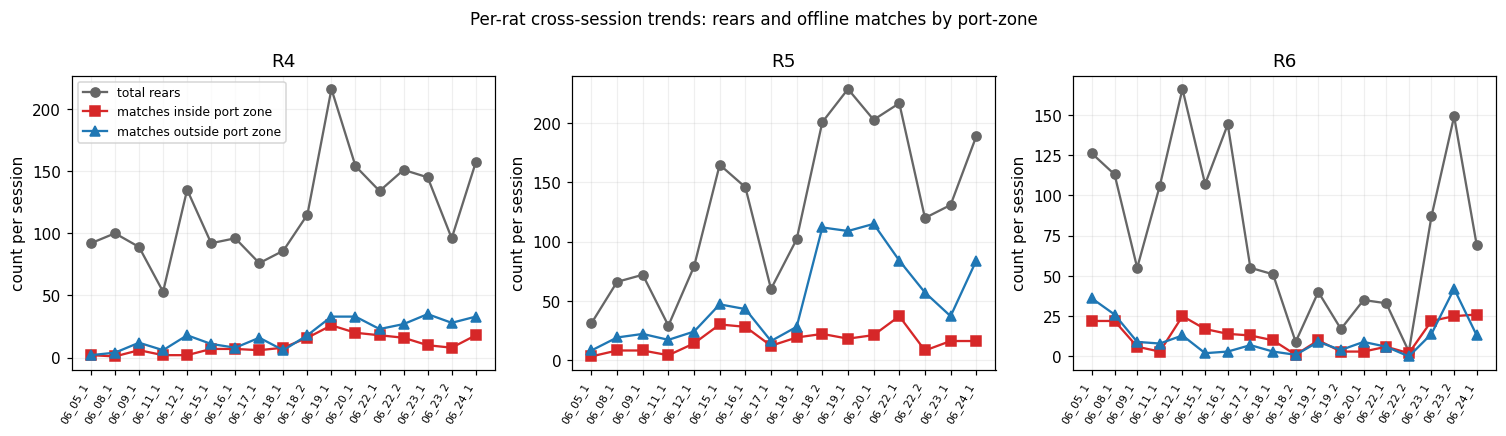

In [145]:
# Local aggregation so this cell stands alone.
by_rat = defaultdict(list)
for (rat, s), r in RESULTS.items():
    by_rat[rat].append((s, r))

# Build a tiny per-rat per-session frame from RESULTS (rears) and `port_dist`.
def _per_session_counts(r):
    n_rears = len(r['rears'])
    off_dist = r['offline_match_dist']
    min_port = r['sd']['min_port_distance']
    # NaN-safe split — drop matches with non-finite port distance.
    finite = np.isfinite(off_dist)
    n_in  = int(((off_dist < min_port) & finite).sum())
    n_out = int(((off_dist >= min_port) & finite).sum())
    return n_rears, n_in, n_out

rats_sorted = sorted(by_rat)
fig, axes = plt.subplots(1, len(rats_sorted), figsize=(4.6 * len(rats_sorted), 4),
                          squeeze=False, sharey=False)
for col, rat in enumerate(rats_sorted):
    ax = axes[0, col]
    sessions_sorted = sorted(by_rat[rat], key=lambda sr: sr[0])
    if not sessions_sorted:
        ax.set_title(f'{rat} — no sessions'); ax.axis('off'); continue
    x_labels = [s[5:] for (s, _) in sessions_sorted]  # 'MM_DD_N'
    rears  = []; inside = []; outside = []
    for (s, r) in sessions_sorted:
        nr, ni, no = _per_session_counts(r)
        rears.append(nr); inside.append(ni); outside.append(no)
    x = np.arange(len(x_labels))
    ax.plot(x, rears,   marker='o', lw=1.5, color='#666',    label='total rears')
    ax.plot(x, inside,  marker='s', lw=1.5, color='#d62728', label='matches inside port zone')
    ax.plot(x, outside, marker='^', lw=1.5, color='#1f77b4', label='matches outside port zone')
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, rotation=60, fontsize=7, ha='right')
    ax.set_title(f'{rat}')
    ax.set_ylabel('count per session')
    ax.grid(alpha=0.2)
    if col == 0:
        ax.legend(fontsize=8, loc='upper left')
fig.suptitle('Per-rat cross-session trends: rears and offline matches by port-zone',
             fontsize=11)
fig.tight_layout()
plt.show()


### First 5 minutes vs rest of session

Same three quantities (total rears, matches inside port zone, matches outside port zone), but split into **first 5 minutes** vs **remainder** of each session. Limited to sessions from `2026_06_12` onward (skips the very early baselines and the first task day, which may be too noisy or short to be informative).

Two panels per rat: left = first 5 min only, right = everything after. Same color scheme as the previous plot.

What to look for:
- If a rat does most of its rears in the first 5 minutes (high left-panel values, low right-panel values), early novelty / exploration is dominating the session. Once the rat habituates, rear rate drops.
- If matches outside the port zone are concentrated in the first 5 min only, the rule may be firing on early exploration postures that aren't representative of steady-state task behavior — worth thinking about whether to use a warmup window in the online rule's bounds-tightening logic.
- If matches outside the port grow in the remainder window across sessions, the rat is learning the task: doing more reward-worthy postures during the productive portion of the session.

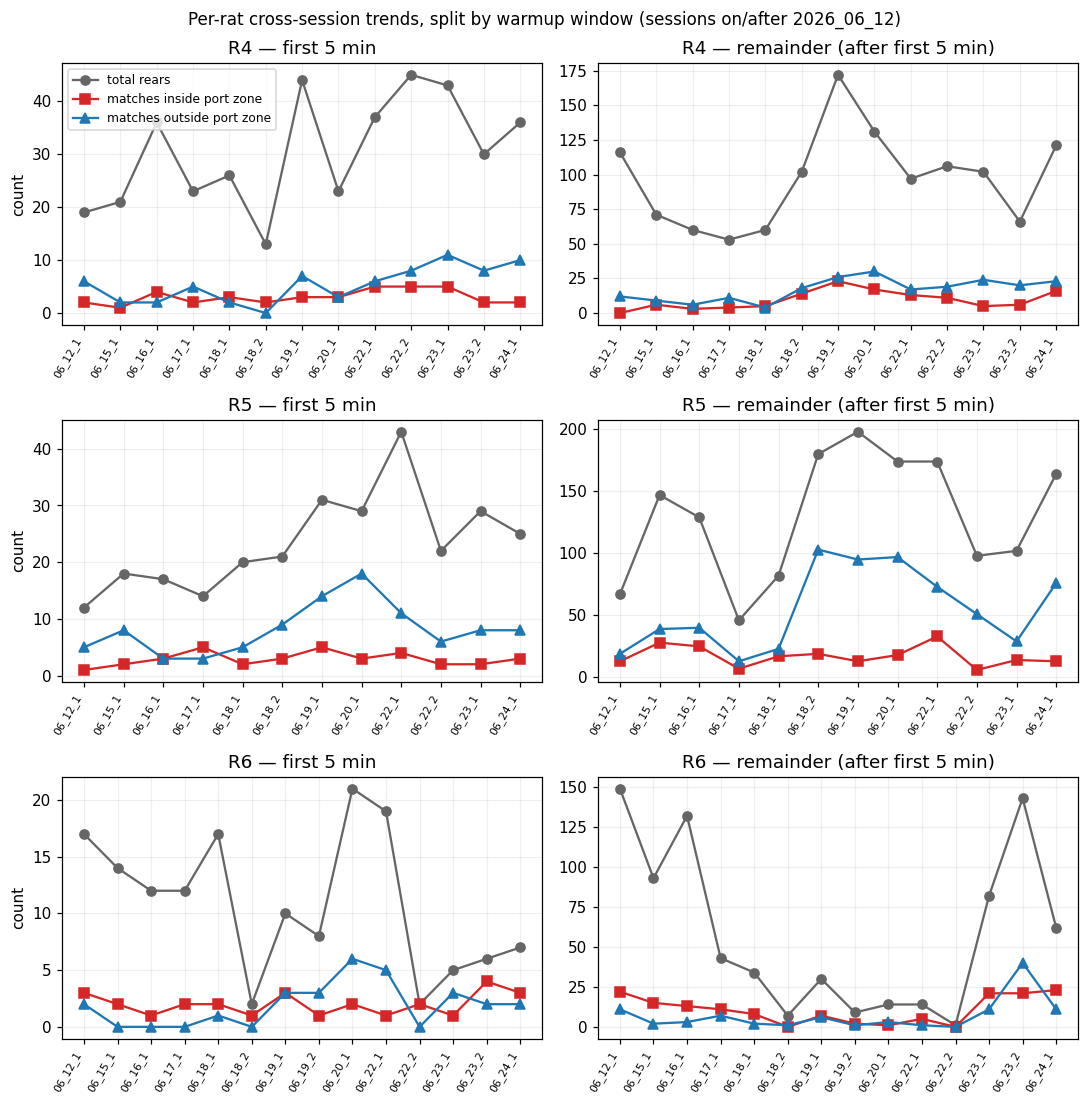

: 

In [ ]:
# Local aggregation so this cell stands alone.
by_rat = defaultdict(list)
for (rat, s), r in RESULTS.items():
    by_rat[rat].append((s, r))

WARMUP_CUTOFF_FRAME = 5 * 60 * SLEAP_HZ   # 6000 frames at 20 Hz = first 5 minutes
DATE_CUTOFF = '2026_06_12'                # sessions on/after this string are included

def _per_session_counts_windowed(r):
    """Return ((rears, in, out) for first 5min, (rears, in, out) for rest)."""
    rears = r['sd']['triang_3d']  # only used for length
    triang_len = len(rears)
    rear_starts = np.array([rs for (rs, _, _) in r['rears']], dtype=int)
    rear_first  = (rear_starts < WARMUP_CUTOFF_FRAME).sum()
    rear_rest   = (rear_starts >= WARMUP_CUTOFF_FRAME).sum()
    # Matches: classify by match_end_cam0 (the same frame used elsewhere).
    match_ends = np.asarray(r['offline_match_cam0'], dtype=int)
    match_dist = np.asarray(r['offline_match_dist'], dtype=float)
    min_port = r['sd']['min_port_distance']
    finite = np.isfinite(match_dist)
    first_mask = (match_ends < WARMUP_CUTOFF_FRAME) & finite
    rest_mask  = (match_ends >= WARMUP_CUTOFF_FRAME) & finite
    inside = match_dist < min_port
    outside = match_dist >= min_port
    first_in   = int((first_mask & inside).sum())
    first_out  = int((first_mask & outside).sum())
    rest_in    = int((rest_mask & inside).sum())
    rest_out   = int((rest_mask & outside).sum())
    return ((int(rear_first),  first_in,  first_out),
            (int(rear_rest),   rest_in,   rest_out))

rats_sorted = sorted(by_rat)
n_cols = 2   # first-5-min | rest
fig, axes = plt.subplots(len(rats_sorted), n_cols,
                          figsize=(5.0 * n_cols, 3.4 * len(rats_sorted)),
                          squeeze=False, sharey=False)

for row, rat in enumerate(rats_sorted):
    # Filter and sort sessions for this rat.
    sessions_filt = sorted([(s, r) for (s, r) in by_rat[rat]
                              if s >= DATE_CUTOFF],
                            key=lambda sr: sr[0])
    if not sessions_filt:
        for col in range(n_cols):
            axes[row, col].set_title(f'{rat} — no sessions in range')
            axes[row, col].axis('off')
        continue
    x_labels = [s[5:] for (s, _) in sessions_filt]
    first_rows, rest_rows = [], []
    for (s, r) in sessions_filt:
        first_t, rest_t = _per_session_counts_windowed(r)
        first_rows.append(first_t); rest_rows.append(rest_t)
    first_arr = np.asarray(first_rows)   # (n_sessions, 3)
    rest_arr  = np.asarray(rest_rows)
    x = np.arange(len(x_labels))
    # Left panel — first 5 min
    ax_l = axes[row, 0]
    ax_l.plot(x, first_arr[:, 0], marker='o', lw=1.5, color='#666',    label='total rears')
    ax_l.plot(x, first_arr[:, 1], marker='s', lw=1.5, color='#d62728', label='matches inside port zone')
    ax_l.plot(x, first_arr[:, 2], marker='^', lw=1.5, color='#1f77b4', label='matches outside port zone')
    ax_l.set_xticks(x); ax_l.set_xticklabels(x_labels, rotation=60, fontsize=7, ha='right')
    ax_l.set_title(f'{rat} — first 5 min'); ax_l.set_ylabel('count')
    ax_l.grid(alpha=0.2)
    if row == 0:
        ax_l.legend(fontsize=8, loc='upper left')
    # Right panel — rest of session
    ax_r = axes[row, 1]
    ax_r.plot(x, rest_arr[:, 0], marker='o', lw=1.5, color='#666')
    ax_r.plot(x, rest_arr[:, 1], marker='s', lw=1.5, color='#d62728')
    ax_r.plot(x, rest_arr[:, 2], marker='^', lw=1.5, color='#1f77b4')
    ax_r.set_xticks(x); ax_r.set_xticklabels(x_labels, rotation=60, fontsize=7, ha='right')
    ax_r.set_title(f'{rat} — remainder (after first 5 min)')
    ax_r.grid(alpha=0.2)

fig.suptitle(f'Per-rat cross-session trends, split by warmup window '
             f'(sessions on/after {DATE_CUTOFF})',
             fontsize=11)
fig.tight_layout()
plt.show()


## 6. Scratch / observations

Use the cell below to jot findings as you click through the plots. The summary DataFrame above is the easiest place to look for outlier sessions to dig into.

In [65]:
# Scratch space — write notes, build ad-hoc plots from RESULTS, SUMMARY, etc.
# Example: pull one session and look at the actual match-frame keypoints,
# or compute a per-session correlation between bounds and match-rate.
# RESULTS[(rat, session)] -> full analysis dict
# SESSIONS                -> list of (rat, session) tuples
# summary                 -> per-session summary DataFrame